# Task 4: SMS Spam Detection with Machine Learning

**Internship:** Oasis Infobyte — Security Analyst

## Objective

Build a machine learning model that classifies SMS text messages as spam or ham (legitimate messages) using the SMS Spam Collection dataset.

## Tools and Libraries

* Python
* Pandas
* Scikit-learn
* Jupyter Notebook
* Matplotlib and Seaborn
*  NLTK
* WordCloud

## Methodology

1. Load the dataset and check the class distribution.
2. Clean and preprocess text (lowercase, remove punctuation and stopwords, stemming).
3. Convert text into numerical features using TF-IDF.
4. Split the data into training and test sets.
5. Train Multinomial Naive Bayes and Logistic Regression models.
6. Evaluate accuracy, precision, recall, F1-score, and confusion matrices.
7. Discuss why recall matters for spam detection.
8. Visualise common spam and ham words with WordClouds.

## Feature Extraction: TF-IDF

TF-IDF (Term Frequency-Inverse Document Frequency) measures how important a word is to a message compared with the whole dataset.

- **Term Frequency (TF):** how often a word appears in a message.
- **Inverse Document Frequency (IDF):** how rare the word is across all messages. Rare words get a higher weight.

A word scores high when it appears often in one message but rarely elsewhere (for example "free" or "winner"). Common words that appear everywhere score low. This turns text into numbers a model can learn from.

## Why is Recall Important for Spam Detection?

Recall = True Positives / (True Positives + False Negatives). It measures the share of actual spam the model catches.

A low recall means spam slips through into the inbox. For a security analyst, a missed spam or phishing message can lead to scams, credential theft or malware. A false alarm (a legitimate message flagged) is usually less costly than a missed attack.

In our results, both models reach a spam precision of 1.00 but a recall of only 0.71 to 0.73. They never wrongly flag a legitimate message, yet they miss roughly 40 of the 149 spam messages. Accuracy alone (0.96) hides this because the dataset is imbalanced.

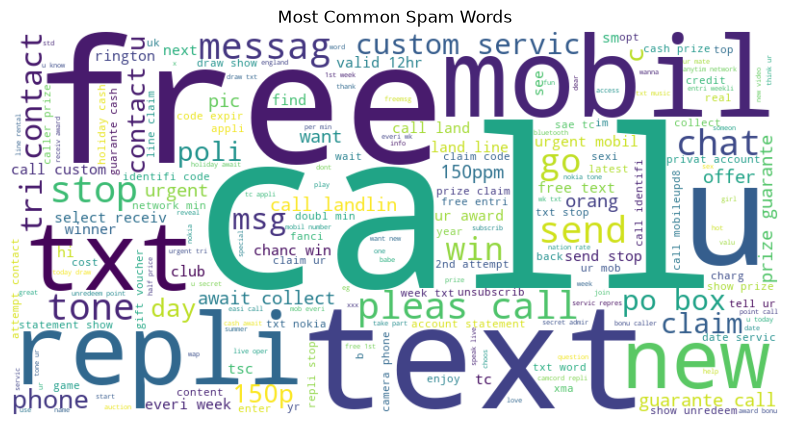

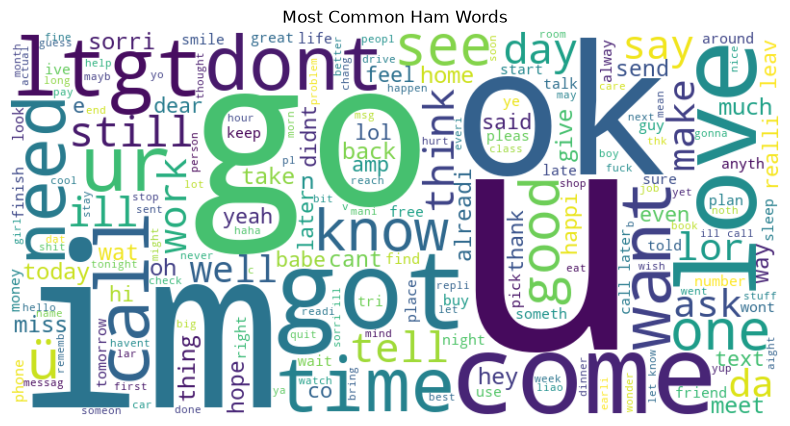

In [1]:
import pandas as pd
import string
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from wordcloud import WordCloud
import matplotlib.pyplot as plt

df = pd.read_csv("SMSSpamCollection", sep="\t", header=None, names=["label", "message"])
stop_words = set(stopwords.words("english"))
stemmer = PorterStemmer()

def clean_text(text):
    text = text.lower()
    text = text.translate(str.maketrans("", "", string.punctuation))
    words = [stemmer.stem(w) for w in text.split() if w not in stop_words]
    return " ".join(words)

df["clean"] = df["message"].apply(clean_text)

for label, title in [("spam", "Most Common Spam Words"), ("ham", "Most Common Ham Words")]:
    text = " ".join(df[df["label"] == label]["clean"])
    wc = WordCloud(width=800, height=400, background_color="white").generate(text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title(title)
    plt.show()

## Conclusion

Both models reached about 96% accuracy. Multinomial Naive Bayes had slightly better spam recall (0.73 vs 0.71) and F1-score (0.84 vs 0.83) than Logistic Regression. Both had perfect spam precision. The main weakness is missed spam, so future work could try class weighting, a lower decision threshold, or an SVM to improve recall.

In [2]:
import pandas as pd

df = pd.read_csv("SMSSpamCollection", sep="\t", header=None, names=["label", "message"])
print(df.shape)
df.head()

(5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [3]:
counts = df["label"].value_counts()
percent = df["label"].value_counts(normalize=True) * 100
print(pd.DataFrame({"count": counts, "percent": percent.round(2)}))

       count  percent
label                
ham     4825    86.59
spam     747    13.41


In [4]:
import re, string, nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

nltk.download("stopwords")
stop_words = set(stopwords.words("english"))
stemmer = PorterStemmer()

def clean_text(text):
    text = text.lower()
    text = text.translate(str.maketrans("", "", string.punctuation))
    words = [stemmer.stem(w) for w in text.split() if w not in stop_words]
    return " ".join(words)

df["clean"] = df["message"].apply(clean_text)
df["target"] = df["label"].map({"ham": 0, "spam": 1})
df[["message", "clean"]].head()

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,message,clean
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazi avail bugi n great world...
1,Ok lar... Joking wif u oni...,ok lar joke wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entri 2 wkli comp win fa cup final tkt 21...
3,U dun say so early hor... U c already then say...,u dun say earli hor u c alreadi say
4,"Nah I don't think he goes to usf, he lives aro...",nah dont think goe usf live around though


from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["target"], test_size=0.2, random_state=42, stratify=df["target"]
)

tfidf = TfidfVectorizer()
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [5]:
import pandas as pd
import string
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

# Load data
df = pd.read_csv("SMSSpamCollection", sep="\t", header=None, names=["label", "message"])

# Clean text
nltk.download("stopwords")
stop_words = set(stopwords.words("english"))
stemmer = PorterStemmer()

def clean_text(text):
    text = text.lower()
    text = text.translate(str.maketrans("", "", string.punctuation))
    words = [stemmer.stem(w) for w in text.split() if w not in stop_words]
    return " ".join(words)

df["clean"] = df["message"].apply(clean_text)
df["target"] = df["label"].map({"ham": 0, "spam": 1})

# Split and TF-IDF
X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["target"], test_size=0.2, random_state=42, stratify=df["target"]
)
tfidf = TfidfVectorizer()
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# Train models
nb = MultinomialNB().fit(X_train_tfidf, y_train)
lr = LogisticRegression(max_iter=1000).fit(X_train_tfidf, y_train)

print("Done. Training rows:", X_train_tfidf.shape[0])

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Done. Training rows: 4457


Naive Bayes
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       966
        spam       1.00      0.73      0.84       149

    accuracy                           0.96      1115
   macro avg       0.98      0.87      0.91      1115
weighted avg       0.97      0.96      0.96      1115



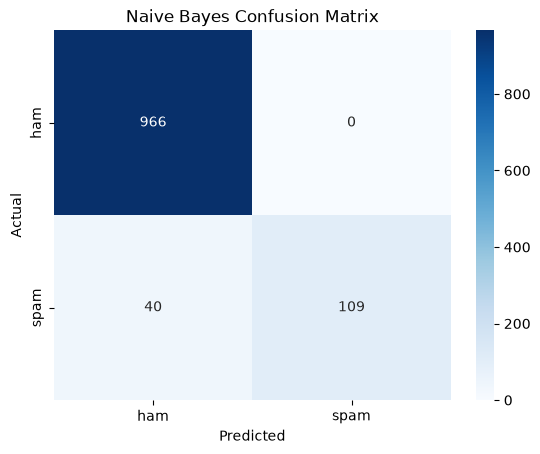

Logistic Regression
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       966
        spam       1.00      0.71      0.83       149

    accuracy                           0.96      1115
   macro avg       0.98      0.86      0.90      1115
weighted avg       0.96      0.96      0.96      1115



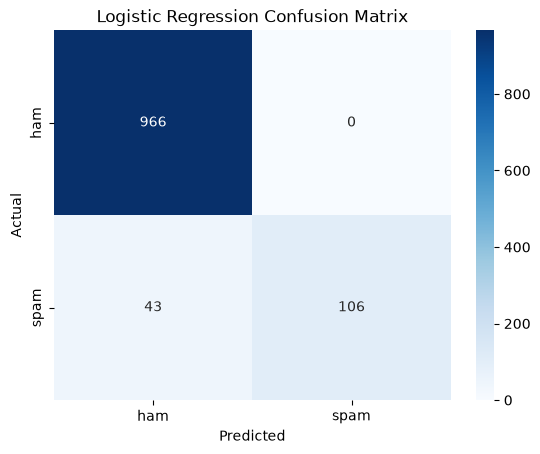

In [6]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns, matplotlib.pyplot as plt

for name, model in [("Naive Bayes", nb), ("Logistic Regression", lr)]:
    pred = model.predict(X_test_tfidf)
    print(name)
    print(classification_report(y_test, pred, target_names=["ham", "spam"]))
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues",
                xticklabels=["ham", "spam"], yticklabels=["ham", "spam"])
    plt.title(f"{name} Confusion Matrix"); plt.xlabel("Predicted"); plt.ylabel("Actual")
    plt.show()